In [11]:
import pandas as pd 
import numpy as np

In [12]:
df = pd.read_csv('Iris.csv')

In [13]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [14]:
df = df.iloc[:,1:]

In [15]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [16]:
from sklearn.preprocessing import LabelEncoder

In [17]:
encoder = LabelEncoder()

In [18]:
df['Species'] = encoder.fit_transform(df['Species'])

In [19]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [20]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [21]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [22]:
import seaborn as sns 
import matplotlib.pyplot as plt

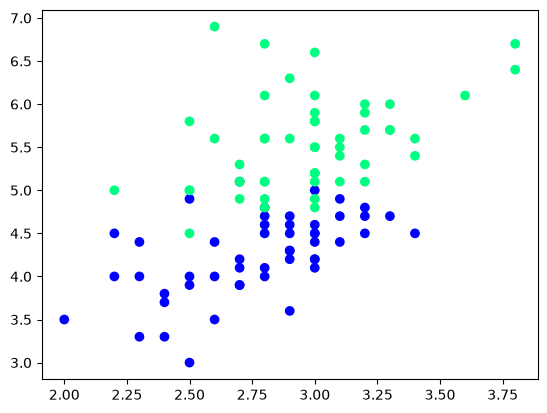

In [23]:
plt.scatter (df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'], cmap='winter')

In [24]:
# taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [25]:
df_train

,SepalWidthCm,PetalLengthCm,Species
52,3.1,4.9,1
85,3.4,4.5,1
101,2.7,5.1,2
80,2.4,3.8,1
143,3.2,5.9,2
69,2.5,3.9,1
57,2.4,3.3,1
118,2.6,6.9,2
61,3.0,4.2,1
110,3.2,5.1,2


In [26]:
df_val

,SepalWidthCm,PetalLengthCm,Species
90,2.6,4.4,1
64,2.9,3.6,1
76,2.8,4.8,1
137,3.1,5.5,2
142,2.7,5.1,2


In [27]:
df_test

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
102,3.0,5.9,2
149,3.0,5.1,2
108,2.5,5.8,2
131,3.8,6.4,2


In [28]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

### Case 1 - Bagging

In [29]:
# Data for tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
df_bag

,SepalWidthCm,PetalLengthCm,Species
101,2.7,5.1,2
80,2.4,3.8,1
110,3.2,5.1,2
143,3.2,5.9,2
69,2.5,3.9,1
69,2.5,3.9,1
118,2.6,6.9,2
110,3.2,5.1,2


In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [31]:
dt_bag1 = DecisionTreeClassifier()

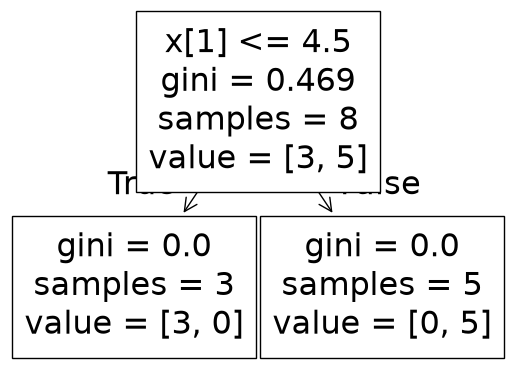

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


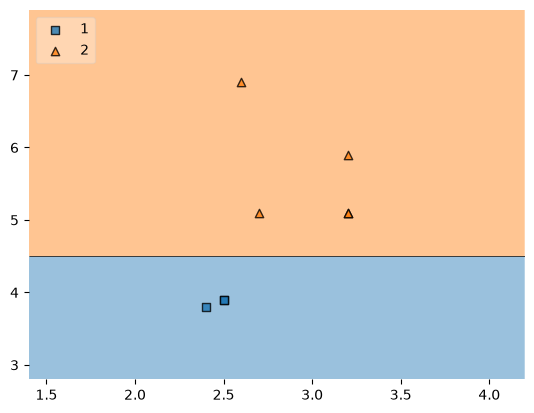

In [41]:
evaluate (dt_bag1,X,y)

In [42]:
# Data for tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
df_bag

,SepalWidthCm,PetalLengthCm,Species
61,3.0,4.2,1
69,2.5,3.9,1
52,3.1,4.9,1
61,3.0,4.2,1
57,2.4,3.3,1
110,3.2,5.1,2
101,2.7,5.1,2
101,2.7,5.1,2


In [43]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf = clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

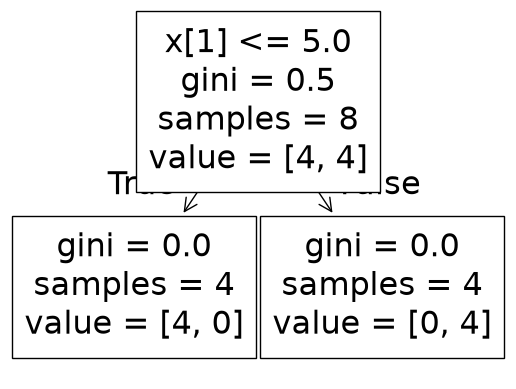

1.0


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


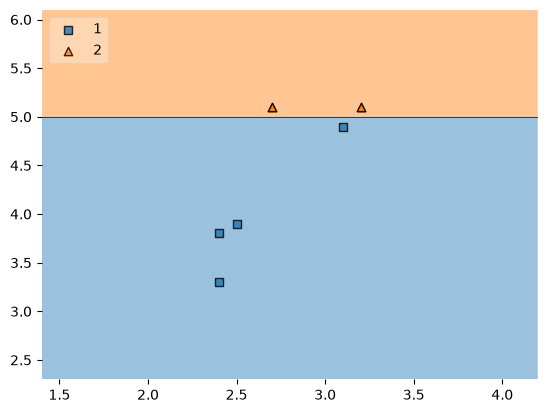

In [46]:
dt_bag2 = DecisionTreeClassifier()
evaluate (dt_bag2,X,y)

In [45]:
# Data for tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
df_bag

,SepalWidthCm,PetalLengthCm,Species
110,3.2,5.1,2
110,3.2,5.1,2
52,3.1,4.9,1
69,2.5,3.9,1
80,2.4,3.8,1
101,2.7,5.1,2
57,2.4,3.3,1
101,2.7,5.1,2


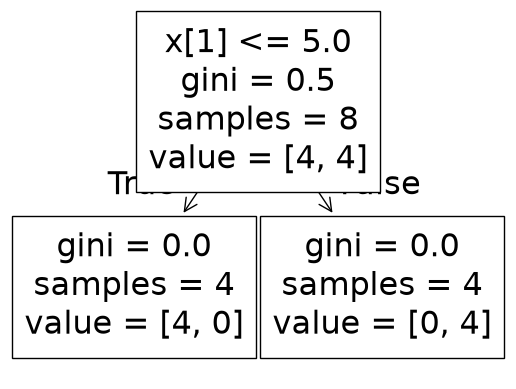

1.0


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


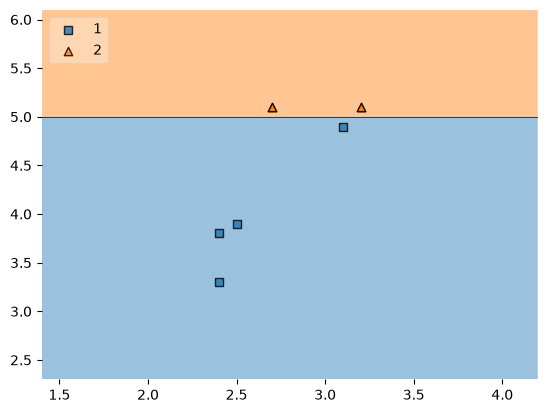

In [47]:
dt_bag3 = DecisionTreeClassifier()
evaluate (dt_bag3,X,y)

In [53]:
df_test

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
102,3.0,5.9,2
149,3.0,5.1,2
108,2.5,5.8,2
131,3.8,6.4,2


In [55]:
print("Predictor 1",dt_bag1.predict(np.array([2.8,6.7]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([3.0,5.9]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([3.0,5.1]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


### pasting

In [56]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
52,3.1,4.9,1
85,3.4,4.5,1
101,2.7,5.1,2
80,2.4,3.8,1
143,3.2,5.9,2
69,2.5,3.9,1
57,2.4,3.3,1
118,2.6,6.9,2
61,3.0,4.2,1
110,3.2,5.1,2


In [57]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
57,2.4,3.3,1
118,2.6,6.9,2
85,3.4,4.5,1
61,3.0,4.2,1
110,3.2,5.1,2
52,3.1,4.9,1
143,3.2,5.9,2
69,2.5,3.9,1


### Random Subspaces

In [58]:
df1 = pd.read_csv('Iris.csv')
df1 = df1.sample(10)

In [59]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
124,125,6.7,3.3,5.7,2.1,Iris-virginica
46,47,5.1,3.8,1.6,0.2,Iris-setosa
91,92,6.1,3.0,4.6,1.4,Iris-versicolor
77,78,6.7,3.0,5.0,1.7,Iris-versicolor
127,128,6.1,3.0,4.9,1.8,Iris-virginica
53,54,5.5,2.3,4.0,1.3,Iris-versicolor
68,69,6.2,2.2,4.5,1.5,Iris-versicolor
71,72,6.1,2.8,4.0,1.3,Iris-versicolor
37,38,4.9,3.1,1.5,0.1,Iris-setosa
114,115,5.8,2.8,5.1,2.4,Iris-virginica


In [60]:
df1.sample(2,replace=True,axis=1)

,PetalWidthCm,PetalWidthCm
124,2.1,2.1
46,0.2,0.2
91,1.4,1.4
77,1.7,1.7
127,1.8,1.8
53,1.3,1.3
68,1.5,1.5
71,1.3,1.3
37,0.1,0.1
114,2.4,2.4


### Random Patches

In [61]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
124,125,6.7,3.3,5.7,2.1,Iris-virginica
46,47,5.1,3.8,1.6,0.2,Iris-setosa
91,92,6.1,3.0,4.6,1.4,Iris-versicolor
77,78,6.7,3.0,5.0,1.7,Iris-versicolor
127,128,6.1,3.0,4.9,1.8,Iris-virginica
53,54,5.5,2.3,4.0,1.3,Iris-versicolor
68,69,6.2,2.2,4.5,1.5,Iris-versicolor
71,72,6.1,2.8,4.0,1.3,Iris-versicolor
37,38,4.9,3.1,1.5,0.1,Iris-setosa
114,115,5.8,2.8,5.1,2.4,Iris-virginica


In [62]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,SepalLengthCm,PetalWidthCm
37,4.9,0.1
127,6.1,1.8
114,5.8,2.4
37,4.9,0.1
124,6.7,2.1
71,6.1,1.3
71,6.1,1.3
91,6.1,1.4
